# Librerías 

In [125]:
import pandas as pd
import matplotlib.pyplot as plt
import re
from collections import Counter
import html


In [126]:
#%pip install scikit-learn
#%pip install spacy

In [127]:
#import spacy

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Dataset

In [128]:
df = pd.read_csv("LandingStage/dataset_migracion_venezolana.csv")

# EDA

Observamos el shape de nuestro dataframe, la presencia de nulos y duplicados y sí están estandarizados los datos.

In [129]:
df

,Unnamed: 0,Titulo,URL,Cuerpo,Autor,Medio,Pais,Fecha
0,0,Vuelven los vuelos de deportación a Venezuela:...,https://www.semana.com/mundo/articulo/vuelven-...,Estados Unidos reanudó este lunes los vuelos d...,Juan Felipe Useche Chacón,Semana,Colombia,"Aug 04, 2026"
1,1,Venezolanos se unen por Colombia tras terremot...,https://www.semana.com/nacion/articulo/venezol...,La solidaridad de los venezolanos por el terre...,Gabriel Salazar López,Semana,Colombia,"Aug 12, 2026"
2,2,Delcy Rodríguez pide a los venezolanos en el e...,https://www.semana.com/mundo/articulo/delcy-ro...,"La presidenta encargada de Venezuela, Delcy Ro...",Juan David Cardozo Maglioni,Semana,Colombia,"Sep 04, 2026"
3,3,"Panamá enviará, por primera vez, un avión dire...",https://www.semana.com/mundo/articulo/panama-e...,"Panamá enviará, por primera vez, un vuelo dire...",Juan David Cardozo Maglioni,Semana,Colombia,"Dec 18, 2025"
4,4,¿Qué pasará con los casi 65.000 migrantes que ...,https://www.semana.com/nacion/bucaramanga/arti...,La decisión de reforzar los controles migrator...,Margarita Briceño Delgado,Semana,Colombia,"Aug 27, 2026"
...,...,...,...,...,...,...,...,...
155,155,EU extiende amparo migratorio para migrantes v...,https://www.milenio.com/internacional/estados-...,El gobierno del presidente estadunidense Joe B...,AFP,Milenio,México,2022-07-11 20:06
156,156,Sale caravana de migrantes venezolanos desde T...,https://www.milenio.com/estados/caravana-migra...,"Una caravana de migrantes, en su mayoría venez...",Julio Navarro Cárdenas,Milenio,México,2022-06-24 13:56
157,157,"Entre calor y fatiga, migrantes quedan varados...",https://www.milenio.com/politica/migrantes-olv...,Suscríbete a Milenio y descarga la edición imp...,Redacción,Milenio,México,2022-06-17 15:37
158,158,"""Plan Vuelta a la Patria"": Maduro promete trip...",https://www.milenio.com/internacional/plan-vue...,"El presidente de Venezuela, Nicolás Maduro, pr...",Editorial Milenio,Milenio,México,2022-02-02 19:47


In [130]:
df.shape

(160, 8)

In [131]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  160 non-null    int64
 1   Titulo      160 non-null    str  
 2   URL         160 non-null    str  
 3   Cuerpo      159 non-null    str  
 4   Autor       160 non-null    str  
 5   Medio       160 non-null    str  
 6   Pais        160 non-null    str  
 7   Fecha       160 non-null    str  
dtypes: int64(1), str(7)
memory usage: 10.1 KB


Distribución de las noticias por país y fuente:

In [132]:
distribucion_pais = df["Pais"].value_counts()
distribucion_medio = df["Medio"].value_counts()

print(distribucion_medio)

print(distribucion_pais)

Medio
Semana     80
Milenio    80
Name: count, dtype: int64
Pais
Colombia    80
México      80
Name: count, dtype: int64


In [133]:
duplicates = df[df.duplicated()]
print(duplicates)

Empty DataFrame
Columns: [Unnamed: 0, Titulo, URL, Cuerpo, Autor, Medio, Pais, Fecha]
Index: []


Busqueda de cuerpo textual duplicado:

In [134]:
df['Cuerpo'].duplicated().any()

np.True_

In [135]:
print("Cuerpos textuales duplicados:", df['Cuerpo'].duplicated().sum())

Cuerpos textuales duplicados: 2


In [136]:
duplicados = df[df['Cuerpo'].duplicated(keep=False)]
duplicados

,Unnamed: 0,Titulo,URL,Cuerpo,Autor,Medio,Pais,Fecha
48,48,Bancamía e IFC se unieron para bancarizar a mi...,https://www.semana.com/economia/articulo/inici...,La Corporaci&oacute;n Financiera Internacional...,Felipe Pérez Saffon,Semana,Colombia,"Aug 31, 2020"
49,49,Bancamía e IFC se unieron para bancarizar a mi...,https://www.semana.com/iniciativa-de-bancamia-...,La Corporaci&oacute;n Financiera Internacional...,Felipe Pérez Saffon,Semana,Colombia,"Aug 31, 2020"
76,76,Santos firmará decreto para “regularizar” más ...,https://www.semana.com/santos-firmara-decreto-...,En una de las que ser&aacute;n sus &uacute;lti...,Angélica María Benavides Gómez,Semana,Colombia,"Jul 25, 2018"
77,77,Santos firmará decreto para “regularizar” más ...,https://www.semana.com/internacional/articulo/...,En una de las que ser&aacute;n sus &uacute;lti...,Angélica María Benavides Gómez,Semana,Colombia,"Jul 25, 2018"


Lo anterior, a parte de detectar que filas contenían un cuerpo textual duplicado, nos ayudó a identificar un problema en las noticias duplicadas: tienen el cuerpo textual "roto", ess decir, no se extrajeron apropiadamente las letras con acento. 

Vale la pena explorar si hay otras noticias que sufren del mismo caso. para ello, se busca que noticias presentan cuerpos textuales que no contienen acentos. La justificación de la solución es la siguiente: en un parrafo extenso en idioma español, es improbable que este presente al menos una letra con acentuación.

In [137]:

# Filas cuyo texto NO contiene ningún acento
sin_acentos = df[~df["Cuerpo"].str.contains(r"[áéíóúÁÉÍÓÚ]", na=False)]

sin_acentos


,Unnamed: 0,Titulo,URL,Cuerpo,Autor,Medio,Pais,Fecha
24,24,Donald Trump les quitó estatuto temporal de pr...,https://www.semana.com/semana-tv/articulo/dona...,NaN,Miguel Rojas,Semana,Colombia,"Jan 31, 2025"
48,48,Bancamía e IFC se unieron para bancarizar a mi...,https://www.semana.com/economia/articulo/inici...,La Corporaci&oacute;n Financiera Internacional...,Felipe Pérez Saffon,Semana,Colombia,"Aug 31, 2020"
49,49,Bancamía e IFC se unieron para bancarizar a mi...,https://www.semana.com/iniciativa-de-bancamia-...,La Corporaci&oacute;n Financiera Internacional...,Felipe Pérez Saffon,Semana,Colombia,"Aug 31, 2020"
76,76,Santos firmará decreto para “regularizar” más ...,https://www.semana.com/santos-firmara-decreto-...,En una de las que ser&aacute;n sus &uacute;lti...,Angélica María Benavides Gómez,Semana,Colombia,"Jul 25, 2018"
77,77,Santos firmará decreto para “regularizar” más ...,https://www.semana.com/internacional/articulo/...,En una de las que ser&aacute;n sus &uacute;lti...,Angélica María Benavides Gómez,Semana,Colombia,"Jul 25, 2018"


Comprobamos que las únicas noticias donde el cuerpo textual no extrajo apropiadamente acentos son aquellas con cuerpos textuales duplicados o nulos.

Longitud de los textos: conviene conocer cuántas palabras contiene cada texto. Podría mostrarnos patrones o irregularidades

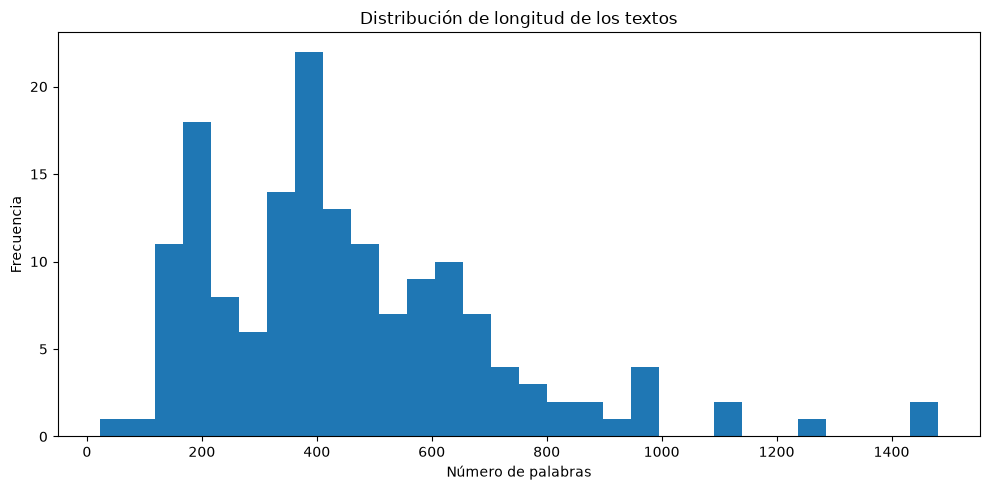

In [138]:

longitudes = (
    df["Cuerpo"]
    .astype(str)
    .str.split()
    .str.len()
)

plt.figure(figsize=(10,5))
plt.hist(longitudes, bins=30)

plt.title("Distribución de longitud de los textos")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [139]:
estadisticas_pais = (
    df.groupby("Pais")["Cuerpo"]
    .apply(lambda x: x.astype(str).str.split().str.len())
    .groupby(level=0)
    .agg(["min", "max", "mean", "median", "std"])
)

estadisticas_pais


,min,max,mean,median,std
Pais,,,,,
Colombia,155.0,1481.0,572.886076,542.0,248.846466
México,22.0,982.0,344.062500,312.0,207.454454


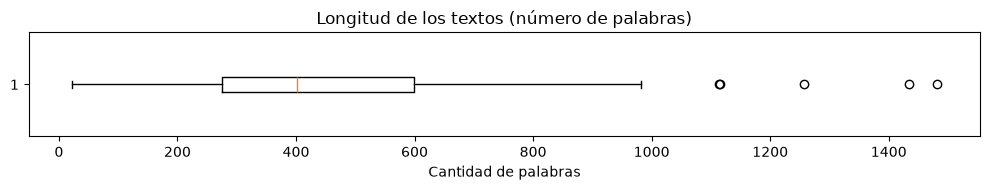

In [140]:

# Longitud en palabras ignorando los nulos
longitudes = (
    df["Cuerpo"]
    .dropna()
    .astype(str)
    .str.split()
    .str.len()
)

plt.figure(figsize=(10, 2))

plt.boxplot(
    longitudes,
    orientation="horizontal"  # reemplaza vert=False
)

plt.title("Longitud de los textos (número de palabras)")
plt.xlabel("Cantidad de palabras")

plt.tight_layout()
plt.show()

Existe un cuerpo textual que solamente tiene 22 palabras

In [141]:
# Longitud en palabras ignorando nulos
longitudes = (
    df["Cuerpo"]
    .dropna()
    .astype(str)
    .str.split()
    .str.len()
)

# Índice del artículo más corto
idx_min = longitudes.idxmin()

print(f"Longitud mínima: {longitudes.loc[idx_min]} palabras\n")
print(df.loc[idx_min, "Cuerpo"])

Longitud mínima: 22 palabras

Suscríbete a Milenio y descarga la edición impresa, suplementos y hemeroteca Para ver esta página correctamente, necesitas activar JavaScript en tu navegador.


Se coló una noticia mexicana que no contiene información útil para el entrenamiento del modelo. 

En lo se refiere a cuerpo textual debemos eliminar cuatro noticias: una sin información y dos repetidas por parte del medio colombiano. Del medio mexicano debemos eliminar una que no contiene texto pertinente.

# Preprocesamiento

## Limpieza e ingeniería de datos

#### Adición de la columna ID 

In [142]:

# Eliminar la primera columna (la columna de ID actual sin título)
df = df.iloc[:, 1:]

# Crear la nueva columna ID
df.insert(
    0,  # posición (primera columna)
    "ID",
    [f"articulo_{i}" for i in range(1, len(df) + 1)]
)

In [143]:
df

,ID,Titulo,URL,Cuerpo,Autor,Medio,Pais,Fecha
0,articulo_1,Vuelven los vuelos de deportación a Venezuela:...,https://www.semana.com/mundo/articulo/vuelven-...,Estados Unidos reanudó este lunes los vuelos d...,Juan Felipe Useche Chacón,Semana,Colombia,"Aug 04, 2026"
1,articulo_2,Venezolanos se unen por Colombia tras terremot...,https://www.semana.com/nacion/articulo/venezol...,La solidaridad de los venezolanos por el terre...,Gabriel Salazar López,Semana,Colombia,"Aug 12, 2026"
2,articulo_3,Delcy Rodríguez pide a los venezolanos en el e...,https://www.semana.com/mundo/articulo/delcy-ro...,"La presidenta encargada de Venezuela, Delcy Ro...",Juan David Cardozo Maglioni,Semana,Colombia,"Sep 04, 2026"
3,articulo_4,"Panamá enviará, por primera vez, un avión dire...",https://www.semana.com/mundo/articulo/panama-e...,"Panamá enviará, por primera vez, un vuelo dire...",Juan David Cardozo Maglioni,Semana,Colombia,"Dec 18, 2025"
4,articulo_5,¿Qué pasará con los casi 65.000 migrantes que ...,https://www.semana.com/nacion/bucaramanga/arti...,La decisión de reforzar los controles migrator...,Margarita Briceño Delgado,Semana,Colombia,"Aug 27, 2026"
...,...,...,...,...,...,...,...,...
155,articulo_156,EU extiende amparo migratorio para migrantes v...,https://www.milenio.com/internacional/estados-...,El gobierno del presidente estadunidense Joe B...,AFP,Milenio,México,2022-07-11 20:06
156,articulo_157,Sale caravana de migrantes venezolanos desde T...,https://www.milenio.com/estados/caravana-migra...,"Una caravana de migrantes, en su mayoría venez...",Julio Navarro Cárdenas,Milenio,México,2022-06-24 13:56
157,articulo_158,"Entre calor y fatiga, migrantes quedan varados...",https://www.milenio.com/politica/migrantes-olv...,Suscríbete a Milenio y descarga la edición imp...,Redacción,Milenio,México,2022-06-17 15:37
158,articulo_159,"""Plan Vuelta a la Patria"": Maduro promete trip...",https://www.milenio.com/internacional/plan-vue...,"El presidente de Venezuela, Nicolás Maduro, pr...",Editorial Milenio,Milenio,México,2022-02-02 19:47


#### Erradicación filas con cuerpo nulo

In [144]:
df = df.dropna(how='any')

#### Erradicación de repetidas

In [145]:
# Eliminar duplicados según el cuerpo de la noticia
df = df.drop_duplicates(subset=["Cuerpo"]).reset_index(drop=True)

print(f"Registros restantes: {len(df)}")


Registros restantes: 157


In [146]:

patron_html = r"&[a-zA-Z]+;"

mask = (
    df["Cuerpo"]
    .fillna("")
    .str.contains(patron_html, regex=True)
)

noticias_html = df[mask]

print(f"Noticias afectadas: {len(noticias_html)}")

Noticias afectadas: 3


In [147]:
noticias_html["Cuerpo"].head()

47    La Corporaci&oacute;n Financiera Internacional...
63    En medio de la actual crisis que atraviesa Est...
74    En una de las que ser&aacute;n sus &uacute;lti...
Name: Cuerpo, dtype: str

In [148]:

noticias_html["Cuerpo"] = (
    noticias_html["Cuerpo"]
    .fillna("")
    .apply(html.unescape)
)

In [149]:
for i, texto in enumerate(noticias_html["Cuerpo"], start=1):
    print(f"\n{'='*100}")
    print(f"NOTICIA {i}")
    print(f"{'='*100}\n")
    print(texto)


NOTICIA 1

La Corporación Financiera Internacional (IFC), miembro del Grupo Banco Mundial, y Bancamía, entidad de la Fundación Microfinanzas BBVA, firmaron un acuerdo de cooperación para fortalecer la oferta de productos y servicios financieros a los migrantes venezolanos, especialmente mujeres, con el objetivo de ayudarlos a integrarse con éxito a las dinámicas sociales y económicas del país.   Impulsado por la Iniciativa de Financiamiento para Mujeres Emprendedoras (The Women Entrepreneurs Finance Initiative, We-Fi), el acuerdo contempla implementar herramientas de acercamiento que permitan conocer las necesidades, desafíos, preferencias, experiencias y aspiraciones de los migrantes venezolanos en todo lo referente al uso de servicios financieros y bancarios. El proyecto cuenta con el apoyo de Fias (Facility for Investment Climate Advisory Services), una iniciativa de colaboración administrada por IFC entre países donantes, organizaciones filantrópicas y el Grupo Banco Mundial, cuyo

In [150]:


df.loc[mask, "Cuerpo"] = (
    df.loc[mask, "Cuerpo"]
    .fillna("")
    .apply(html.unescape)
)

In [151]:
mask = (
    df["Cuerpo"]
    .fillna("")
    .str.contains(r"&[a-zA-Z]+;", regex=True)
)

print(f"Noticias aún afectadas: {mask.sum()}")

Noticias aún afectadas: 0


Debemos estandarizar las fechas y anonimizar a los autores:

#### Estandarización de las fechas 

In [152]:
df["Fecha"] = pd.to_datetime(
    df["Fecha"],
    format="mixed",   # útil para formatos distintos
    errors="coerce"
)

df["Fecha"] = df["Fecha"].dt.strftime("%Y-%m-%d")

In [153]:
df

,ID,Titulo,URL,Cuerpo,Autor,Medio,Pais,Fecha
0,articulo_1,Vuelven los vuelos de deportación a Venezuela:...,https://www.semana.com/mundo/articulo/vuelven-...,Estados Unidos reanudó este lunes los vuelos d...,Juan Felipe Useche Chacón,Semana,Colombia,2026-08-04
1,articulo_2,Venezolanos se unen por Colombia tras terremot...,https://www.semana.com/nacion/articulo/venezol...,La solidaridad de los venezolanos por el terre...,Gabriel Salazar López,Semana,Colombia,2026-08-12
2,articulo_3,Delcy Rodríguez pide a los venezolanos en el e...,https://www.semana.com/mundo/articulo/delcy-ro...,"La presidenta encargada de Venezuela, Delcy Ro...",Juan David Cardozo Maglioni,Semana,Colombia,2026-09-04
3,articulo_4,"Panamá enviará, por primera vez, un avión dire...",https://www.semana.com/mundo/articulo/panama-e...,"Panamá enviará, por primera vez, un vuelo dire...",Juan David Cardozo Maglioni,Semana,Colombia,2025-12-18
4,articulo_5,¿Qué pasará con los casi 65.000 migrantes que ...,https://www.semana.com/nacion/bucaramanga/arti...,La decisión de reforzar los controles migrator...,Margarita Briceño Delgado,Semana,Colombia,2026-08-27
...,...,...,...,...,...,...,...,...
152,articulo_156,EU extiende amparo migratorio para migrantes v...,https://www.milenio.com/internacional/estados-...,El gobierno del presidente estadunidense Joe B...,AFP,Milenio,México,2022-07-11
153,articulo_157,Sale caravana de migrantes venezolanos desde T...,https://www.milenio.com/estados/caravana-migra...,"Una caravana de migrantes, en su mayoría venez...",Julio Navarro Cárdenas,Milenio,México,2022-06-24
154,articulo_158,"Entre calor y fatiga, migrantes quedan varados...",https://www.milenio.com/politica/migrantes-olv...,Suscríbete a Milenio y descarga la edición imp...,Redacción,Milenio,México,2022-06-17
155,articulo_159,"""Plan Vuelta a la Patria"": Maduro promete trip...",https://www.milenio.com/internacional/plan-vue...,"El presidente de Venezuela, Nicolás Maduro, pr...",Editorial Milenio,Milenio,México,2022-02-02


#### Anonimización de los autores

In [154]:
autores_unicos = df["Autor"].unique()

In [155]:
df_autores = pd.DataFrame({
    "ID_Autor": [f"AutorID_{i}" for i in range(1, len(autores_unicos) + 1)],
    "Autor": autores_unicos
}
)

In [156]:
df_autores.to_csv(
    "AuthorAnon/dataset_autores_anonimizados.csv",
    index = False,
    encoding= "utf-8-sig"
)

df_autores


,ID_Autor,Autor
0,AutorID_1,Juan Felipe Useche Chacón
1,AutorID_2,Gabriel Salazar López
2,AutorID_3,Juan David Cardozo Maglioni
3,AutorID_4,Margarita Briceño Delgado
4,AutorID_5,Deivis Ramírez Miranda
...,...,...
86,AutorID_87,César Velázquez
87,AutorID_88,Milenio Digital
88,AutorID_89,Editorial Milenio
89,AutorID_90,Jaime Zambrano


In [157]:
df_autores.to_csv(
    "AuthorAnon/dataset_autores_anonimizados.csv",
    index = False,
    encoding= "utf-8-sig"
)

In [158]:
# Crear diccionario Autor -> AutorID
mapa_autores = dict(zip(df_autores["Autor"], df_autores["ID_Autor"]))

# Reemplazar nombres por IDs
df["Autor"] = df["Autor"].map(mapa_autores)

In [159]:
df

,ID,Titulo,URL,Cuerpo,Autor,Medio,Pais,Fecha
0,articulo_1,Vuelven los vuelos de deportación a Venezuela:...,https://www.semana.com/mundo/articulo/vuelven-...,Estados Unidos reanudó este lunes los vuelos d...,AutorID_1,Semana,Colombia,2026-08-04
1,articulo_2,Venezolanos se unen por Colombia tras terremot...,https://www.semana.com/nacion/articulo/venezol...,La solidaridad de los venezolanos por el terre...,AutorID_2,Semana,Colombia,2026-08-12
2,articulo_3,Delcy Rodríguez pide a los venezolanos en el e...,https://www.semana.com/mundo/articulo/delcy-ro...,"La presidenta encargada de Venezuela, Delcy Ro...",AutorID_3,Semana,Colombia,2026-09-04
3,articulo_4,"Panamá enviará, por primera vez, un avión dire...",https://www.semana.com/mundo/articulo/panama-e...,"Panamá enviará, por primera vez, un vuelo dire...",AutorID_3,Semana,Colombia,2025-12-18
4,articulo_5,¿Qué pasará con los casi 65.000 migrantes que ...,https://www.semana.com/nacion/bucaramanga/arti...,La decisión de reforzar los controles migrator...,AutorID_4,Semana,Colombia,2026-08-27
...,...,...,...,...,...,...,...,...
152,articulo_156,EU extiende amparo migratorio para migrantes v...,https://www.milenio.com/internacional/estados-...,El gobierno del presidente estadunidense Joe B...,AutorID_70,Milenio,México,2022-07-11
153,articulo_157,Sale caravana de migrantes venezolanos desde T...,https://www.milenio.com/estados/caravana-migra...,"Una caravana de migrantes, en su mayoría venez...",AutorID_82,Milenio,México,2022-06-24
154,articulo_158,"Entre calor y fatiga, migrantes quedan varados...",https://www.milenio.com/politica/migrantes-olv...,Suscríbete a Milenio y descarga la edición imp...,AutorID_62,Milenio,México,2022-06-17
155,articulo_159,"""Plan Vuelta a la Patria"": Maduro promete trip...",https://www.milenio.com/internacional/plan-vue...,"El presidente de Venezuela, Nicolás Maduro, pr...",AutorID_89,Milenio,México,2022-02-02


### Etiquetado


Usamos el servicio labelbox para añadir rigurosidad al etiquetado:

In [160]:
#from to_labelbox import enviar_a_labelbox

#enviar_a_labelbox(df)

Después de etiquetar, se exportan las etiquetas desde labelbox para adjuntarlas en el dataframe:

In [161]:
df_labels =pd.read_csv("LandingStage/labels.csv")
df_labels

,ID,sentimiento,Acceso_a_servicios,Empleo_y_economía,Integración_social,Otros,Politica_migratoria,Seguridad,Transito_migratorio
0,articulo_155,Neutro,0,0,0,0,0,0,1
1,articulo_154,Neutro,1,0,0,0,1,1,1
2,articulo_19,Neutro,0,0,0,0,1,0,1
3,articulo_11,Positivo,0,0,1,0,0,0,1
4,articulo_153,Neutro,0,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...
155,articulo_3,Neutro,0,0,0,0,1,0,0
156,articulo_7,Positivo,0,0,1,1,0,0,0
157,articulo_156,Neutro,0,0,0,0,1,0,0
158,articulo_160,Neutro,0,0,0,0,1,0,1


### unión de las labels al dataframe

In [162]:
df = df.merge(
    df_labels,
    on="ID",
    how="left"
)

In [163]:
df

,ID,Titulo,URL,Cuerpo,Autor,Medio,Pais,Fecha,sentimiento,Acceso_a_servicios,Empleo_y_economía,Integración_social,Otros,Politica_migratoria,Seguridad,Transito_migratorio
0,articulo_1,Vuelven los vuelos de deportación a Venezuela:...,https://www.semana.com/mundo/articulo/vuelven-...,Estados Unidos reanudó este lunes los vuelos d...,AutorID_1,Semana,Colombia,2026-08-04,Neutro,1,0,0,0,0,0,0
1,articulo_2,Venezolanos se unen por Colombia tras terremot...,https://www.semana.com/nacion/articulo/venezol...,La solidaridad de los venezolanos por el terre...,AutorID_2,Semana,Colombia,2026-08-12,Negativo,0,0,0,0,0,1,0
2,articulo_3,Delcy Rodríguez pide a los venezolanos en el e...,https://www.semana.com/mundo/articulo/delcy-ro...,"La presidenta encargada de Venezuela, Delcy Ro...",AutorID_3,Semana,Colombia,2026-09-04,Neutro,0,0,0,0,1,0,0
3,articulo_4,"Panamá enviará, por primera vez, un avión dire...",https://www.semana.com/mundo/articulo/panama-e...,"Panamá enviará, por primera vez, un vuelo dire...",AutorID_3,Semana,Colombia,2025-12-18,Positivo,1,1,1,0,0,0,0
4,articulo_5,¿Qué pasará con los casi 65.000 migrantes que ...,https://www.semana.com/nacion/bucaramanga/arti...,La decisión de reforzar los controles migrator...,AutorID_4,Semana,Colombia,2026-08-27,Neutro,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,articulo_156,EU extiende amparo migratorio para migrantes v...,https://www.milenio.com/internacional/estados-...,El gobierno del presidente estadunidense Joe B...,AutorID_70,Milenio,México,2022-07-11,Neutro,0,0,0,0,1,0,0
153,articulo_157,Sale caravana de migrantes venezolanos desde T...,https://www.milenio.com/estados/caravana-migra...,"Una caravana de migrantes, en su mayoría venez...",AutorID_82,Milenio,México,2022-06-24,Neutro,0,0,0,0,0,0,1
154,articulo_158,"Entre calor y fatiga, migrantes quedan varados...",https://www.milenio.com/politica/migrantes-olv...,Suscríbete a Milenio y descarga la edición imp...,AutorID_62,Milenio,México,2022-06-17,Neutro,0,0,0,1,0,0,0
155,articulo_159,"""Plan Vuelta a la Patria"": Maduro promete trip...",https://www.milenio.com/internacional/plan-vue...,"El presidente de Venezuela, Nicolás Maduro, pr...",AutorID_89,Milenio,México,2022-02-02,Negativo,0,0,1,0,1,1,0


Para mayor claridad, valdría la pena dejar la columna de cuerpo textual detras de aquellas de sentimiento y encuadre:

In [164]:
cols = list(df.columns)

cols.remove("Cuerpo")

pos_sentimiento = cols.index("sentimiento")

cols.insert(pos_sentimiento, "Cuerpo")

df = df[cols]

In [165]:
df 

,ID,Titulo,URL,Autor,Medio,Pais,Fecha,Cuerpo,sentimiento,Acceso_a_servicios,Empleo_y_economía,Integración_social,Otros,Politica_migratoria,Seguridad,Transito_migratorio
0,articulo_1,Vuelven los vuelos de deportación a Venezuela:...,https://www.semana.com/mundo/articulo/vuelven-...,AutorID_1,Semana,Colombia,2026-08-04,Estados Unidos reanudó este lunes los vuelos d...,Neutro,1,0,0,0,0,0,0
1,articulo_2,Venezolanos se unen por Colombia tras terremot...,https://www.semana.com/nacion/articulo/venezol...,AutorID_2,Semana,Colombia,2026-08-12,La solidaridad de los venezolanos por el terre...,Negativo,0,0,0,0,0,1,0
2,articulo_3,Delcy Rodríguez pide a los venezolanos en el e...,https://www.semana.com/mundo/articulo/delcy-ro...,AutorID_3,Semana,Colombia,2026-09-04,"La presidenta encargada de Venezuela, Delcy Ro...",Neutro,0,0,0,0,1,0,0
3,articulo_4,"Panamá enviará, por primera vez, un avión dire...",https://www.semana.com/mundo/articulo/panama-e...,AutorID_3,Semana,Colombia,2025-12-18,"Panamá enviará, por primera vez, un vuelo dire...",Positivo,1,1,1,0,0,0,0
4,articulo_5,¿Qué pasará con los casi 65.000 migrantes que ...,https://www.semana.com/nacion/bucaramanga/arti...,AutorID_4,Semana,Colombia,2026-08-27,La decisión de reforzar los controles migrator...,Neutro,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,articulo_156,EU extiende amparo migratorio para migrantes v...,https://www.milenio.com/internacional/estados-...,AutorID_70,Milenio,México,2022-07-11,El gobierno del presidente estadunidense Joe B...,Neutro,0,0,0,0,1,0,0
153,articulo_157,Sale caravana de migrantes venezolanos desde T...,https://www.milenio.com/estados/caravana-migra...,AutorID_82,Milenio,México,2022-06-24,"Una caravana de migrantes, en su mayoría venez...",Neutro,0,0,0,0,0,0,1
154,articulo_158,"Entre calor y fatiga, migrantes quedan varados...",https://www.milenio.com/politica/migrantes-olv...,AutorID_62,Milenio,México,2022-06-17,Suscríbete a Milenio y descarga la edición imp...,Neutro,0,0,0,1,0,0,0
155,articulo_159,"""Plan Vuelta a la Patria"": Maduro promete trip...",https://www.milenio.com/internacional/plan-vue...,AutorID_89,Milenio,México,2022-02-02,"El presidente de Venezuela, Nicolás Maduro, pr...",Negativo,0,0,1,0,1,1,0


In [168]:
df.to_csv(
    "LandingStage/dataset_migracion_venezolana_labeled.csv",
    index=False
)

# Procesamiento

In [166]:
#!python -m spacy download es_core_news_sm

In [167]:
# Cargar modelo en español
nlp = spacy.load('es_core_news_sm')

NameError: name 'spacy' is not defined